In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')


In [2]:
df=pd.read_csv("C:/Users/disha/Downloads/insurance.csv")

In [3]:
#eda
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

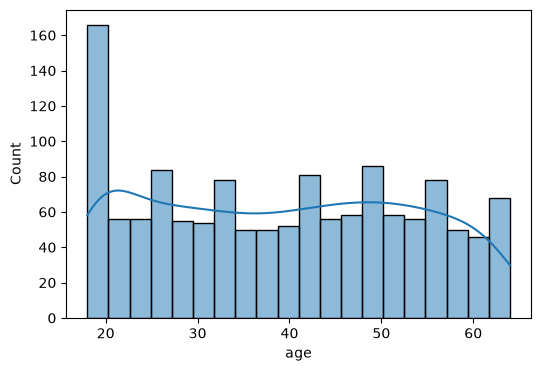

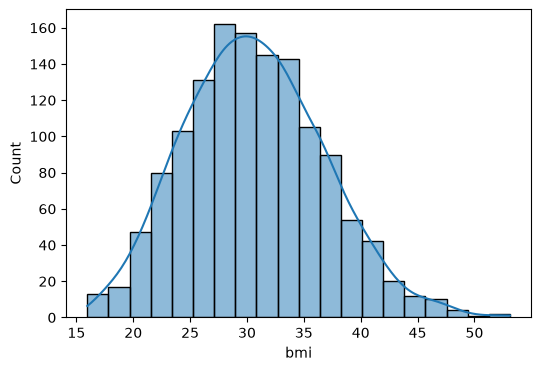

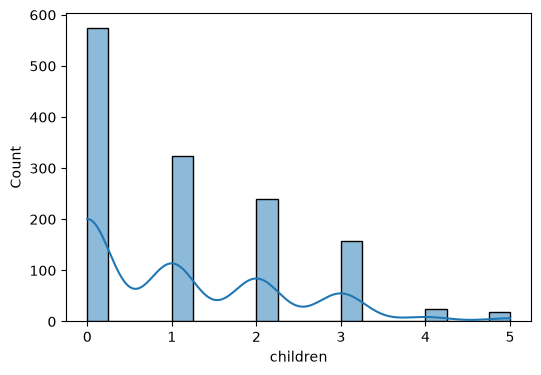

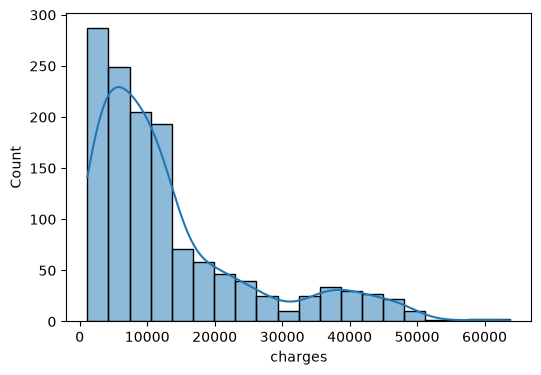

In [8]:
numeric_col=['age',  'bmi', 'children', 'charges']
for col in numeric_col:
  plt.figure(figsize=(6,4))
  sns.histplot(df[col],kde=True,bins=20)
  plt.show()

<Axes: xlabel='children', ylabel='count'>

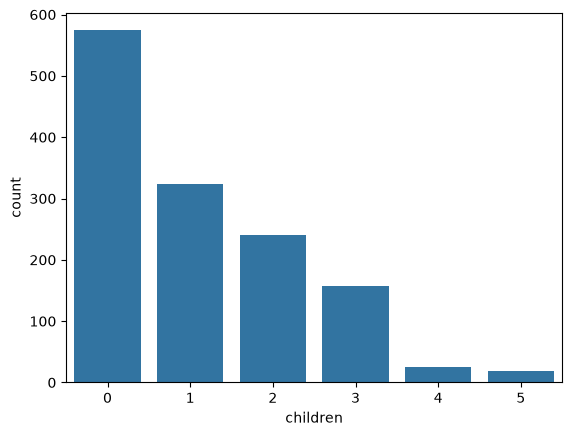

In [9]:
sns.countplot(x=df['children'])

<Axes: xlabel='sex', ylabel='count'>

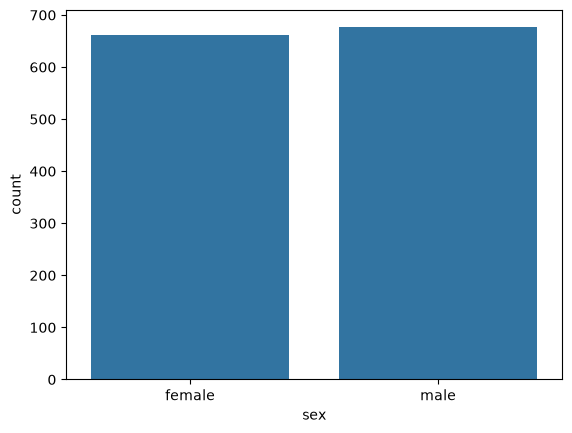

In [10]:
sns.countplot(x=df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

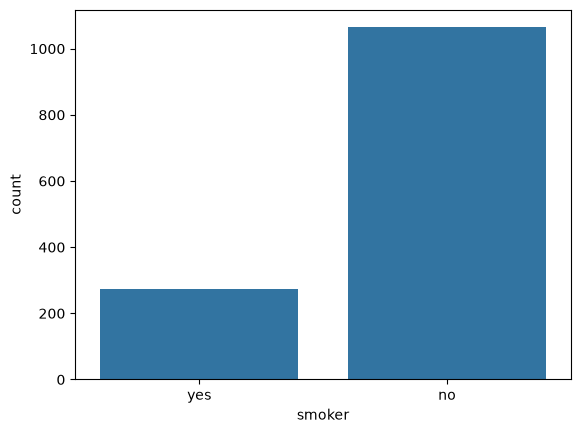

In [11]:
sns.countplot(x=df['smoker'])

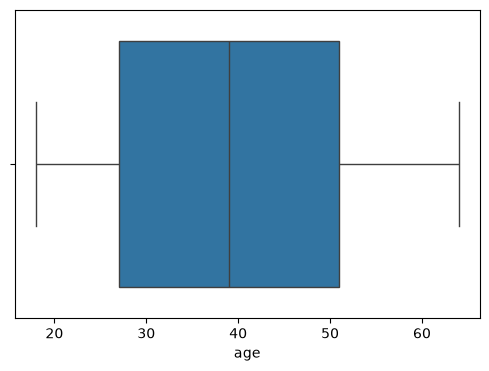

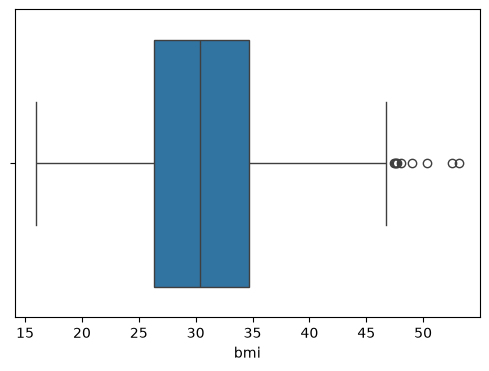

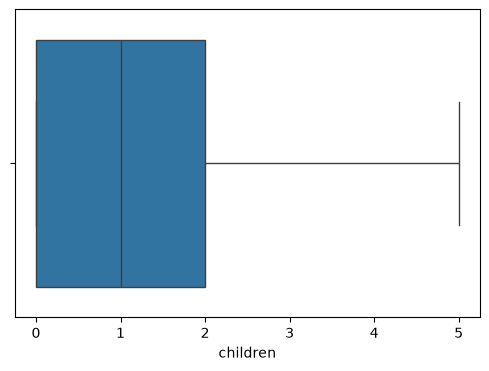

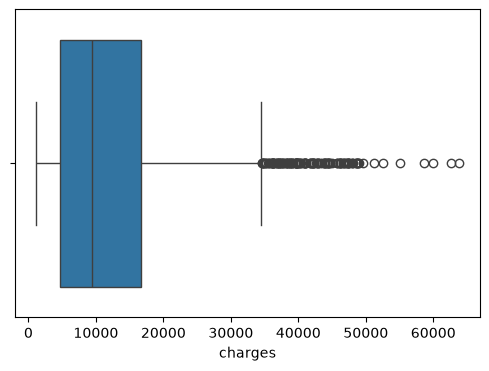

In [12]:
for col in numeric_col:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])
  plt.show()


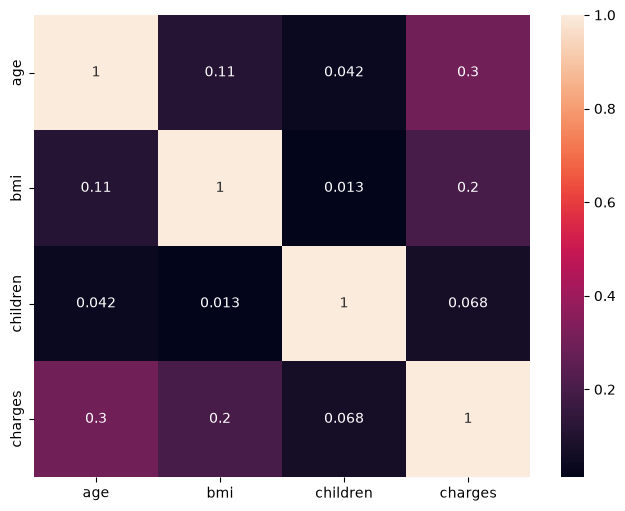

In [13]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

In [14]:
#data cleaning and preprocessing
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [15]:
df.drop_duplicates(inplace=True)

In [16]:
df['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [17]:
print(df['sex'].unique())

<StringArray>
['female', 'male']
Length: 2, dtype: str


In [18]:

df['sex'] = df['sex'].map({
    "male": 0,
    "female": 1
})
print(df.head())

   age  sex     bmi  children smoker     region      charges
0   19    1  27.900         0    yes  southwest  16884.92400
1   18    0  33.770         1     no  southeast   1725.55230
2   28    0  33.000         3     no  southeast   4449.46200
3   33    0  22.705         0     no  northwest  21984.47061
4   32    0  28.880         0     no  northwest   3866.85520


In [19]:
df['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [20]:
df['smoker']=df['smoker'].map({
    "yes":1,
    "no":0
})
print(df.head())

   age  sex     bmi  children  smoker     region      charges
0   19    1  27.900         0       1  southwest  16884.92400
1   18    0  33.770         1       0  southeast   1725.55230
2   28    0  33.000         3       0  southeast   4449.46200
3   33    0  22.705         0       0  northwest  21984.47061
4   32    0  28.880         0       0  northwest   3866.85520


In [21]:
df.rename(columns={
    "sex":"is_female",
    "smoker":"is_smoker"
},inplace=True)
print(df.head())

   age  is_female     bmi  children  is_smoker     region      charges
0   19          1  27.900         0          1  southwest  16884.92400
1   18          0  33.770         1          0  southeast   1725.55230
2   28          0  33.000         3          0  southeast   4449.46200
3   33          0  22.705         0          0  northwest  21984.47061
4   32          0  28.880         0          0  northwest   3866.85520


In [22]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [23]:
df=pd.get_dummies(df,columns=['region'],drop_first=True)
print(df.head())

   age  is_female     bmi  children  is_smoker      charges  region_northwest  \
0   19          1  27.900         0          1  16884.92400             False   
1   18          0  33.770         1          0   1725.55230             False   
2   28          0  33.000         3          0   4449.46200             False   
3   33          0  22.705         0          0  21984.47061              True   
4   32          0  28.880         0          0   3866.85520              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


In [25]:
df=df.astype(int)
print(df.head())

   age  is_female  bmi  children  is_smoker  charges  region_northwest  \
0   19          1   27         0          1    16884                 0   
1   18          0   33         1          0     1725                 0   
2   28          0   33         3          0     4449                 0   
3   33          0   22         0          0    21984                 1   
4   32          0   28         0          0     3866                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  


<Axes: xlabel='bmi', ylabel='Count'>

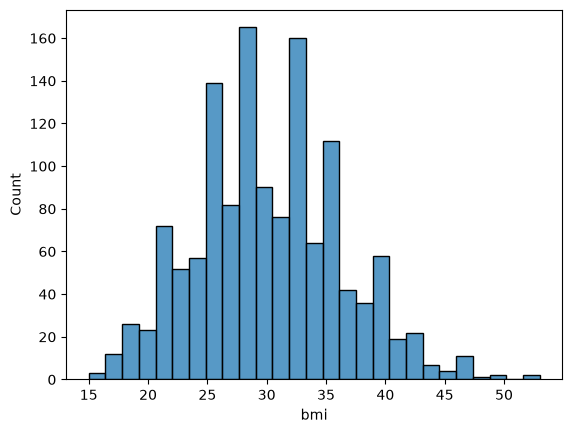

In [26]:
#feature engineering and extraction
sns.histplot(df['bmi'])

In [ ]:
df['bmi_category']=pd.cut(
    df['bmi'],
    bins=[0,18.5,24.9,29.9,float('inf')],
    labels=['underweight','healthy','overweight','obese']
)


In [28]:
print(df.head())

   age  is_female  bmi  children  is_smoker  charges  region_northwest  \
0   19          1   27         0          1    16884                 0   
1   18          0   33         1          0     1725                 0   
2   28          0   33         3          0     4449                 0   
3   33          0   22         0          0    21984                 1   
4   32          0   28         0          0     3866                 1   

   region_southeast  region_southwest bmi_category  
0                 0                 1   overweight  
1                 1                 0        obese  
2                 1                 0        obese  
3                 0                 0      healthy  
4                 0                 0   overweight  


In [29]:
df = pd.get_dummies(df, columns=['bmi_category'], drop_first=True)

In [30]:
df = df.astype(int)

In [31]:
df.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_healthy', 'bmi_category_overweight',
       'bmi_category_obese'],
      dtype='str')

In [32]:
from sklearn.preprocessing import StandardScaler
cols_to_scale = ['age', 'bmi', 'children']
scaler = StandardScaler()
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])


In [35]:
df.head()
df.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_healthy', 'bmi_category_overweight',
       'bmi_category_obese'],
      dtype='str')

In [ ]:

from scipy.stats import pearsonr

# ----------------------------------
# Pearson Correlation Calculation
# ----------------------------------

# List of features to check against target
selected_features = [
    'age', 'bmi', 'children', 'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
     'bmi_category_overweight', 'bmi_category_obese',
]

# Calculate Pearson correlation
correlations = {
    feature: pearsonr(df[feature], df['charges'])[0]
    for feature in selected_features
}

# Convert to DataFrame for display
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])

# Show the results
correlation_df.sort_values(by='Pearson Correlation', ascending=False)


KeyError: 'bmi_category_Normal'

In [48]:
cat_features = [
    'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
     'bmi_category_healthy', 'bmi_category_overweight', 'bmi_category_obese',
]
print(df.columns)

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_healthy', 'bmi_category_overweight', 'bmi_category_obese',
       'charges_bin'],
      dtype='str')


In [49]:
from scipy.stats import chi2_contingency
import pandas as pd

# Define significance level
alpha = 0.05

# Bin the target variable
df['charges_bin'] = pd.qcut(df['charges'], q=4, labels=False)

# Run Chi-Square test
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df[col], df['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

# Convert to DataFrame
chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df


,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_obese,8.515711,0.036473,Reject Null (Keep Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_overweight,4.25149,0.235557,Accept Null (Drop Feature)
bmi_category_healthy,3.708088,0.29476,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


In [51]:
final_df = df[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges','region_southeast','bmi_category_obese','region_northwest']]

In [52]:
print(final_df)

           age  is_female       bmi  children  is_smoker  charges  \
0    -1.440418          1 -0.517949 -0.909234          1    16884   
1    -1.511647          0  0.462463 -0.079442          0     1725   
2    -0.799350          0  0.462463  1.580143          0     4449   
3    -0.443201          0 -1.334960 -0.909234          0    21984   
4    -0.514431          0 -0.354547 -0.909234          0     3866   
...        ...        ...       ...       ...        ...      ...   
1333  0.767704          0 -0.027743  1.580143          0    10600   
1334 -1.511647          1  0.135659 -0.909234          0     2205   
1335 -1.511647          1  0.952670 -0.909234          0     1629   
1336 -1.297958          1 -0.844753 -0.909234          0     2007   
1337  1.551231          1 -0.191145 -0.909234          1    29141   

      region_southeast  bmi_category_obese  region_northwest  
0                    0                   0                 0  
1                    1                   1   

In [55]:
from sklearn.model_selection import train_test_split

In [56]:
X=final_df.drop('charges',axis=1)
y=final_df['charges']

In [57]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [58]:
from sklearn.linear_model import LinearRegression

In [60]:
model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[3489. , 71.69, 565.07,...,-279.1 ,3286.01, -45.7 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['age','is_female','bmi',...,'region_southeast','bmi_category_obese', 'region_northwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6785
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [61]:
y_pred=model.predict(X_test)

In [62]:
y_pred

array([ 7872.60430837,  5395.9756102 , 14583.12511214, 32435.14684602,
        8956.02260947, 13337.05519493, 30212.76350939,  1418.90934563,
       11196.68139874,  9989.72359987, 10788.50407611, 32112.9152209 ,
       31564.48673015, 16243.87430021, 10300.89189051,  8505.06779259,
        5503.46089073, 32464.13379806,  3321.51549208,  3877.38977161,
        4759.77480883, 28810.89415243, 13870.40865428, 29556.455122  ,
       31487.38994615,  6314.24302791, 35024.88188912, 37894.44985496,
       12505.23786681, 14255.51448172,  7587.93258879, 13049.30282556,
         517.97952518, 11355.74639273, 37580.91300612, 13371.6114411 ,
        3724.04476678,  4508.52567092, 31481.7004095 ,  8009.90203388,
        6089.91553588, 30419.83055099, 35276.32144552, 13115.25767768,
        7948.57814942,  3002.36451676,  5188.16747509,  7635.77498509,
        3492.93903127, 10390.18580314,  7820.48277948, 10520.07342659,
       30345.22401831,  4688.08750936, 11691.84715745, 11448.12095514,
      

In [66]:
from sklearn.metrics import r2_score

r2=r2_score(y_test,y_pred)
print(r2)
n=X_test.shape[0]
p=X_test.shape[1]
adjusted_r2=1-((1-r2)*(n-1)/(n-p-1))
adjusted_r2

0.8040145984242553


0.7979609952867806

In [ ]:
----------------------
------------------------Car price prediction-------------------

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [70]:
df=pd.read_csv("C:/Users/disha/Downloads/ford.csv")
print(df.head())

     model  year  price transmission  mileage fuelType  tax   mpg  engineSize
0   Fiesta  2017  12000    Automatic    15944   Petrol  150  57.7         1.0
1    Focus  2018  14000       Manual     9083   Petrol  150  57.7         1.0
2    Focus  2017  13000       Manual    12456   Petrol  150  57.7         1.0
3   Fiesta  2019  17500       Manual    10460   Petrol  145  40.3         1.5
4   Fiesta  2019  16500    Automatic     1482   Petrol  145  48.7         1.0


In [71]:
print(df.shape)

(17966, 9)


In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  str    
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  str    
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  str    
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), str(3)
memory usage: 1.2 MB


In [73]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [74]:
df.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

<Axes: xlabel='price', ylabel='Count'>

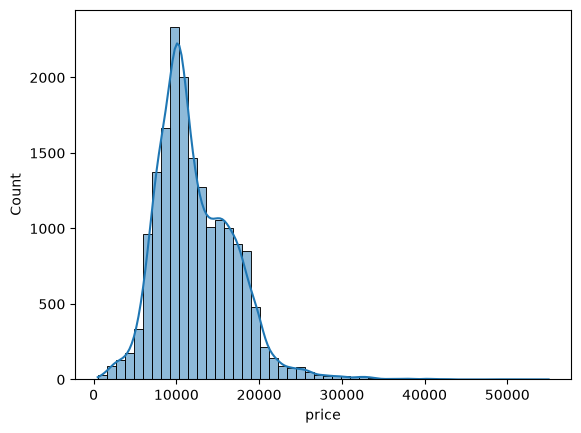

In [76]:
#Eda
sns.histplot(df['price'],bins=50,kde=True)

<Axes: >

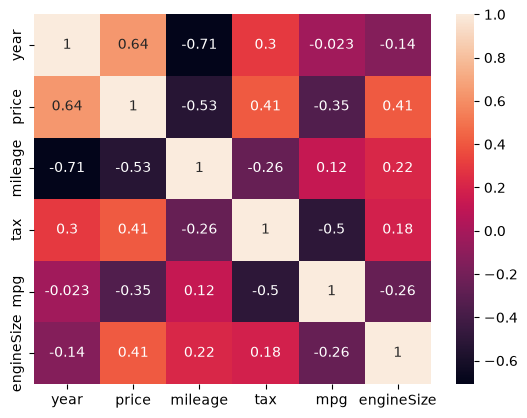

In [79]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, '1996'),
  Text(1, 0, '1998'),
  Text(2, 0, '2000'),
  Text(3, 0, '2002'),
  Text(4, 0, '2003'),
  Text(5, 0, '2004'),
  Text(6, 0, '2005'),
  Text(7, 0, '2006'),
  Text(8, 0, '2007'),
  Text(9, 0, '2008'),
  Text(10, 0, '2009'),
  Text(11, 0, '2010'),
  Text(12, 0, '2011'),
  Text(13, 0, '2012'),
  Text(14, 0, '2013'),
  Text(15, 0, '2014'),
  Text(16, 0, '2015'),
  Text(17, 0, '2016'),
  Text(18, 0, '2017'),
  Text(19, 0, '2018'),
  Text(20, 0, '2019'),
  Text(21, 0, '2020'),
  Text(22, 0, '2060')])

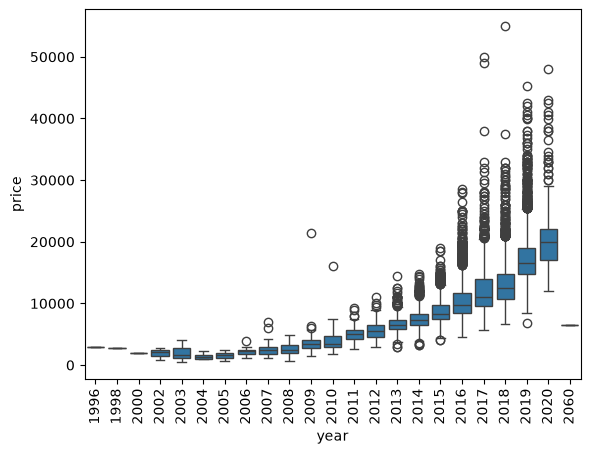

In [81]:
sns.boxplot(data=df,x='year',y='price')
plt.xticks(rotation=90)

<Axes: xlabel='mileage', ylabel='price'>

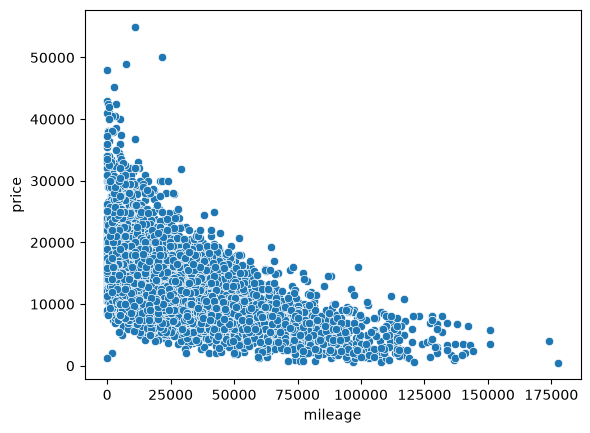

In [83]:
sns.scatterplot(data=df,x='mileage',y='price')

<Axes: xlabel='engineSize', ylabel='price'>

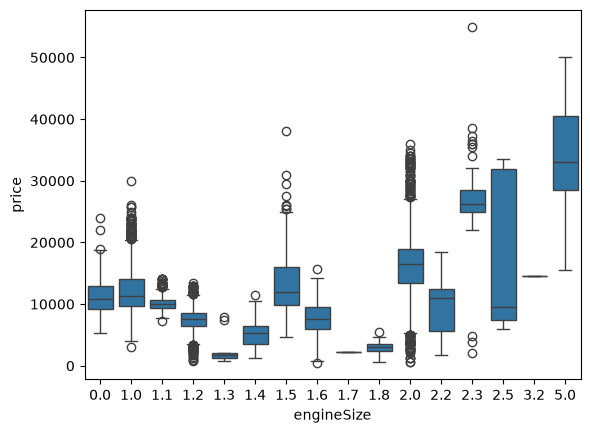

In [84]:
sns.boxplot(data=df,x='engineSize',y='price')

In [85]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')

<Axes: xlabel='transmission', ylabel='price'>

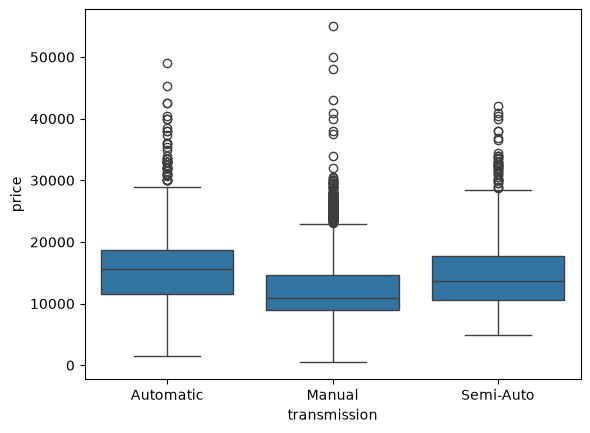

In [86]:
sns.boxplot(data=df,x='transmission',y='price')

<Axes: xlabel='fuelType', ylabel='price'>

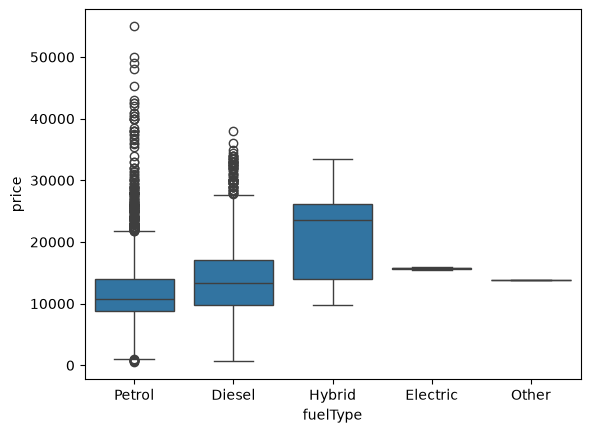

In [87]:
sns.boxplot(data=df,x='fuelType',y='price')

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23],
 [Text(0, 0, ' Fiesta'),
  Text(1, 0, ' Focus'),
  Text(2, 0, ' Puma'),
  Text(3, 0, ' Kuga'),
  Text(4, 0, ' EcoSport'),
  Text(5, 0, ' C-MAX'),
  Text(6, 0, ' Mondeo'),
  Text(7, 0, ' Ka+'),
  Text(8, 0, ' Tourneo Custom'),
  Text(9, 0, ' S-MAX'),
  Text(10, 0, ' B-MAX'),
  Text(11, 0, ' Edge'),
  Text(12, 0, ' Tourneo Connect'),
  Text(13, 0, ' Grand C-MAX'),
  Text(14, 0, ' KA'),
  Text(15, 0, ' Galaxy'),
  Text(16, 0, ' Mustang'),
  Text(17, 0, ' Grand Tourneo Connect'),
  Text(18, 0, ' Fusion'),
  Text(19, 0, ' Ranger'),
  Text(20, 0, ' Streetka'),
  Text(21, 0, ' Escort'),
  Text(22, 0, ' Transit Tourneo'),
  Text(23, 0, 'Focus')])

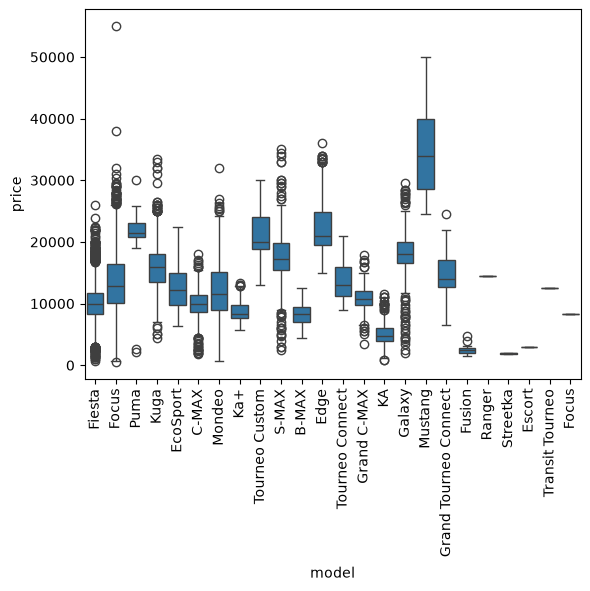

In [89]:
sns.boxplot(x=df['model'],y=df['price'])
plt.xticks(rotation=90)

In [90]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')

In [91]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


<Axes: xlabel='price', ylabel='tax'>

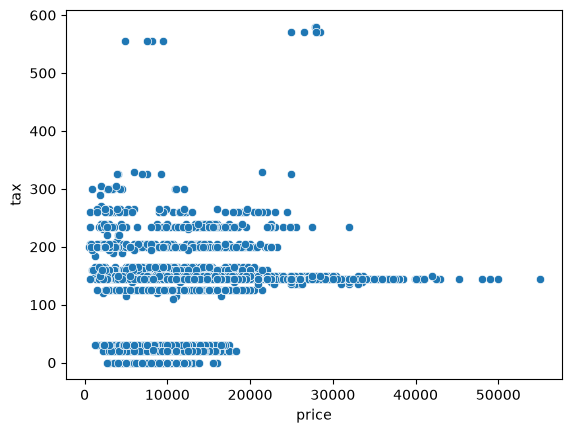

In [94]:
sns.scatterplot(data=df,x='price',y='tax')

<Axes: xlabel='price', ylabel='mpg'>

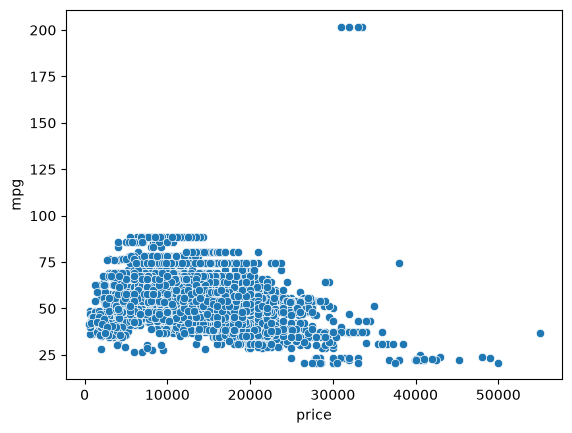

In [96]:
sns.scatterplot(data=df,x='price',y='mpg')

In [100]:
X=df.drop(columns=['price'])
y=df['price']

In [101]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')

In [105]:
x_one_encode=pd.get_dummies(X,columns=['model','transmission','fuelType'],drop_first=True)
x_one_encode=x_one_encode.astype(int)
x_one_encode

,year,mileage,tax,mpg,engineSize,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,model_ Fiesta,...,model_ Tourneo Connect,model_ Tourneo Custom,model_ Transit Tourneo,model_Focus,transmission_Manual,transmission_Semi-Auto,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,2017,15944,150,57,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,2018,9083,150,57,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,2017,12456,150,57,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,2019,10460,145,40,1,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
4,2019,1482,145,48,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17961,2017,16700,150,47,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
17962,2014,40700,30,57,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
17963,2015,7010,20,67,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
17964,2018,5007,145,57,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1


In [109]:
from sklearn.preprocessing import LabelEncoder
encode=LabelEncoder()
columns=['model','transmission','fuelType']
xlabel=X
for i in columns:
    xlabel[i]=encode.fit_transform(xlabel[i])

In [110]:
xlabel

,model,year,transmission,mileage,fuelType,tax,mpg,engineSize
0,5,2017,0,15944,4,150,57.7,1.0
1,6,2018,1,9083,4,150,57.7,1.0
2,6,2017,1,12456,4,150,57.7,1.0
3,5,2019,1,10460,4,145,40.3,1.5
4,5,2019,0,1482,4,145,48.7,1.0
...,...,...,...,...,...,...,...,...
17961,0,2017,1,16700,4,150,47.1,1.4
17962,0,2014,1,40700,4,30,57.7,1.0
17963,6,2015,1,7010,0,20,67.3,1.6
17964,11,2018,1,5007,4,145,57.7,1.2


In [112]:
from sklearn.preprocessing import StandardScaler

In [115]:
numerical=['year','mileage','tax','mpg']
scalar=StandardScaler()
x_one_encode[numerical]=scalar.fit_transform(x_one_encode[numerical])
x_one_encode

,year,mileage,tax,mpg,engineSize,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,model_ Fiesta,...,model_ Tourneo Connect,model_ Tourneo Custom,model_ Transit Tourneo,model_Focus,transmission_Manual,transmission_Semi-Auto,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,0.065128,-0.380998,0.591358,-0.042122,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,0.552866,-0.733359,0.591358,-0.042122,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.065128,-0.560132,0.591358,-0.042122,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,1.040605,-0.662640,0.510727,-1.721198,1,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
4,1.040605,-1.123724,0.510727,-0.931045,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17961,0.065128,-0.342172,0.591358,-1.029814,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
17962,-1.398088,0.890398,-1.343791,-0.042122,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
17963,-0.910349,-0.839822,-1.505053,0.945569,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
17964,0.552866,-0.942690,0.510727,-0.042122,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1


In [120]:
xlabel.columns

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

In [121]:
xlabel[['model','year','transmission','mileage','fuelType','tax','mpg','engineSize']]=scalar.fit_transform(xlabel[['model','year','transmission','mileage','fuelType','tax','mpg','engineSize']])

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [117]:
xlabel=scalar.fit_transform(xlabel)

In [118]:
xlabel

array([[-0.46069913,  0.06512772, -2.67003231, ...,  0.59135805,
        -0.02044162, -0.81138621],
       [-0.21147687,  0.55286624,  0.04135139, ...,  0.59135805,
        -0.02044162, -0.81138621],
       [-0.21147687,  0.06512772,  0.04135139, ...,  0.59135805,
        -0.02044162, -0.81138621],
       ...,
       [-0.21147687, -0.91034931,  0.04135139, ..., -1.50505332,
         0.92766777,  0.57636151],
       [ 1.03463446,  0.55286624,  0.04135139, ...,  0.51072684,
        -0.02044162, -0.34880364],
       [ 4.02530164, -0.91034931,  0.04135139, ..., -1.47280084,
        -0.02044162, -0.81138621]], shape=(17966, 8))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [122]:
X_train,X_test,y_train,y_test=train_test_split(x_one_encode,test_size=0.20,random_state=42)

ValueError: not enough values to unpack (expected 4, got 2)

In [123]:
X_train, X_test, y_train, y_test = train_test_split(
    x_one_encode,
    y,
    test_size=0.20,
    random_state=42
)

In [124]:
model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](34,)","[ 2061.43,-1305.27, -20.89,...,10347.61, 717.46,-1181.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](34,)","['year','mileage','tax',...,'fuelType_Hybrid','fuelType_Other', 'fuelType_Petrol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9155
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,34
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(34)


In [125]:
y_pred=model.predict(X_test)

In [126]:
y_pred

array([ 6866.3580764 ,  9347.6810129 ,  9362.18320785, ...,
       31454.95287518,  9781.20362786, 15253.49970894], shape=(3594,))

In [127]:
y_test

17610     6995
7076      8999
1713      7998
1611      5491
16830     3790
         ...  
7731     22000
11655    13699
10536    24979
11885    10500
4032     19718
Name: price, Length: 3594, dtype: int64

In [129]:
r2=r2_score(y_test,y_pred)
r2

0.8464177711972801

In [130]:
n=X_test.shape[0]
p=X_test.shape[1]
adjusted_r2=1-((1-r2)*(n-1)/(n-p-1))
adjusted_r2

0.8449505624927867

In [131]:
X_train, X_test, y_train, y_test = train_test_split(
    xlabel,
    y,
    test_size=0.20,
    random_state=42
)

In [132]:
model2=LinearRegression()
model2.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 109.17, 2413.79, -99.76,..., 60.75,-1054.1 , 1813.73]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.229e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[179.52,170.73,135. ,..., 82.55, 61.05, 50.1 ]"


In [134]:
y_pred=model2.predict(X_test)
y_pred

array([ 6152.07567671,  9374.39134399,  9464.92264335, ...,
       21787.05312508,  9776.43926374, 15806.24990719], shape=(3594,))

In [135]:
r2=r2_score(y_test,y_pred)
r2

0.7365884288851354

--------------------------------------------------------------
-------------------------------------------------------------------
--------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------
---------------------------------------------------------------------------------------------------------
Ecomarce

import numpy as np


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
#Load data set 
df=pd.read_csv("C:/Users/disha/Downloads/uncleaned_linear_regression_ecommerce_5000.csv")
print(df.head())

  Customer_ID  Customer_Age Product_Category Product_Price  Quantity  \
0   CUST01593          53.0      Electronics      31117.75         6   
1   CUST00003          34.0         Clothing      43615.38         1   
2   CUST00350          70.0           Sports      44491.91         4   
3   CUST00902          21.0   Home & Kitchen      16169.28         2   
4   CUST00740          44.0      Electronics      36741.27         3   

  Discount_Percent  Review_Rating Delivery_Days  Previous_Purchases  \
0               19            3.0             7                14.0   
1               30            2.0             3                 8.0   
2               25            2.0             8                 0.0   
3               16            3.0            11                 5.0   
4                6            2.0             2                28.0   

   Customer_Tenure_Months Payment_Method    City           Order_Date  \
0                      48    Credit Card   Delhi  2025-04-18 04:26:

In [70]:
print(df.shape)

(5080, 14)


In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5080 entries, 0 to 5079
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             5080 non-null   str    
 1   Customer_Age            4950 non-null   float64
 2   Product_Category        5080 non-null   str    
 3   Product_Price           4977 non-null   str    
 4   Quantity                5080 non-null   int64  
 5   Discount_Percent        4990 non-null   str    
 6   Review_Rating           4979 non-null   float64
 7   Delivery_Days           4980 non-null   str    
 8   Previous_Purchases      4976 non-null   float64
 9   Customer_Tenure_Months  5080 non-null   int64  
 10  Payment_Method          4987 non-null   str    
 11  City                    4990 non-null   str    
 12  Order_Date              5080 non-null   str    
 13  Purchase_Amount         5059 non-null   float64
dtypes: float64(4), int64(2), str(8)
memory usage: 555.8

In [72]:
df.describe()

,Customer_Age,Quantity,Review_Rating,Previous_Purchases,Customer_Tenure_Months,Purchase_Amount
count,4950.000000,5080.000000,4979.000000,4976.000000,5080.000000,5059.000000
mean,43.818586,3.519488,2.958024,14.925241,30.754331,76699.097262
std,15.956631,1.704844,1.446948,9.041125,17.286357,60230.584623
min,-10.000000,1.000000,0.000000,0.000000,1.000000,58.670000
25%,30.000000,2.000000,2.000000,7.000000,16.000000,28116.650000
50%,44.000000,4.000000,3.000000,15.000000,31.000000,61767.440000
75%,57.000000,5.000000,4.000000,23.000000,46.000000,112272.230000
max,150.000000,6.000000,10.000000,30.000000,60.000000,294921.250000


In [73]:
df.isnull().sum()

Customer_ID                 0
Customer_Age              130
Product_Category            0
Product_Price             103
Quantity                    0
Discount_Percent           90
Review_Rating             101
Delivery_Days             100
Previous_Purchases        104
Customer_Tenure_Months      0
Payment_Method             93
City                       90
Order_Date                  0
Purchase_Amount            21
dtype: int64

In [74]:
df.duplicated().sum()

np.int64(80)

In [47]:
df.drop_duplicates()

,Customer_ID,Customer_Age,Product_Category,Product_Price,Quantity,Discount_Percent,Review_Rating,Delivery_Days,Previous_Purchases,Customer_Tenure_Months,Payment_Method,City,Order_Date,Purchase_Amount
0,CUST01593,53.0,Electronics,31117.75,6,19,3.0,7,14.0,48,Credit Card,Delhi,2025-04-18 04:26:00,152372.77
1,CUST00003,34.0,Clothing,43615.38,1,30,2.0,3,8.0,9,Credit Card,MUMBAI,2025-07-05 17:26:00,31108.74
2,CUST00350,70.0,Sports,44491.91,4,25,2.0,8,0.0,29,UPI,Nagpur,2025-12-17 17:57:00,133600.19
3,CUST00902,21.0,Home & Kitchen,16169.28,2,16,3.0,11,5.0,40,Net Banking,Pune,2025-10-05 12:30:00,28227.29
4,CUST00740,44.0,Electronics,36741.27,3,6,2.0,2,28.0,42,Debit Card,Delhi,2024-09-20 11:31:00,106166.14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5075,CUST01373,50.0,books,47164.99,1,28,4.0,6,24.0,4,Debit Card,Nashik,2024-07-02 02:30:00,35747.57
5076,CUST01789,43.0,Grocery,2440.39,1,19,5.0,7,23.0,40,credit card,NaN,2025-02-04 03:25:00,4491.50
5077,CUST01039,43.0,Home & Kitchen,42824.74,2,26,1.0,5,3.0,26,Net Banking,Nashik,2024-05-25 09:02:00,64487.05
5078,CUST00179,67.0,Sports,3543.8,3,18,2.0,11,23.0,11,Debit Card,Nagpur,2024-01-02 01:52:00,10366.62


In [75]:
print(df.head(20))
df['Product_Price']=(df["Product_Price"].astype(str)
                     .str.replace("₹","",regex=False))

   Customer_ID  Customer_Age Product_Category Product_Price  Quantity  \
0    CUST01593          53.0      Electronics      31117.75         6   
1    CUST00003          34.0         Clothing      43615.38         1   
2    CUST00350          70.0           Sports      44491.91         4   
3    CUST00902          21.0   Home & Kitchen      16169.28         2   
4    CUST00740          44.0      Electronics      36741.27         3   
5    CUST00230          70.0           Beauty     ₹31936.61         2   
6    CUST00642          21.0          Grocery      33802.72         5   
7    CUST00874          38.0           Beauty      10100.85         4   
8    CUST00603          46.0   Home & Kitchen      19451.98         1   
9    CUST00022          48.0   Home & Kitchen      40604.48         2   
10   CUST01500          48.0           Sports       6931.04         6   
11   CUST00031          47.0           Sports           NaN         6   
12   CUST00118          62.0            Books      

In [77]:
df["Product_Price"]=pd.to_numeric(df['Product_Price'] ,errors="coerce")
df["Product_Price"].dtype

dtype('float64')

In [78]:
df["Product_Price"].isnull().sum()
df["Product_Price"]=df["Product_Price"].fillna(df["Product_Price"].median())

In [65]:
print(df.head(20))



   Customer_ID  Customer_Age Product_Category Product_Price  Quantity  \
0    CUST01593          53.0      Electronics      31117.75         6   
1    CUST00003          34.0         Clothing      43615.38         1   
2    CUST00350          70.0           Sports      44491.91         4   
3    CUST00902          21.0   Home & Kitchen      16169.28         2   
4    CUST00740          44.0      Electronics      36741.27         3   
5    CUST00230          70.0           Beauty     ₹31936.61         2   
6    CUST00642          21.0          Grocery      33802.72         5   
7    CUST00874          38.0           Beauty      10100.85         4   
8    CUST00603          46.0   Home & Kitchen      19451.98         1   
9    CUST00022          48.0   Home & Kitchen      40604.48         2   
10   CUST01500          48.0           Sports       6931.04         6   
11   CUST00031          47.0           Sports           NaN         6   
12   CUST00118          62.0            Books      

In [79]:
print(df.dtypes)

Customer_ID                   str
Customer_Age              float64
Product_Category              str
Product_Price             float64
Quantity                    int64
Discount_Percent              str
Review_Rating             float64
Delivery_Days                 str
Previous_Purchases        float64
Customer_Tenure_Months      int64
Payment_Method                str
City                          str
Order_Date                    str
Purchase_Amount           float64
dtype: object


In [80]:
print(df.isnull().sum())

Customer_ID                 0
Customer_Age              130
Product_Category            0
Product_Price               0
Quantity                    0
Discount_Percent           90
Review_Rating             101
Delivery_Days             100
Previous_Purchases        104
Customer_Tenure_Months      0
Payment_Method             93
City                       90
Order_Date                  0
Purchase_Amount            21
dtype: int64


In [81]:
print(df.head())

  Customer_ID  Customer_Age Product_Category  Product_Price  Quantity  \
0   CUST01593          53.0      Electronics       31117.75         6   
1   CUST00003          34.0         Clothing       43615.38         1   
2   CUST00350          70.0           Sports       44491.91         4   
3   CUST00902          21.0   Home & Kitchen       16169.28         2   
4   CUST00740          44.0      Electronics       36741.27         3   

  Discount_Percent  Review_Rating Delivery_Days  Previous_Purchases  \
0               19            3.0             7                14.0   
1               30            2.0             3                 8.0   
2               25            2.0             8                 0.0   
3               16            3.0            11                 5.0   
4                6            2.0             2                28.0   

   Customer_Tenure_Months Payment_Method    City           Order_Date  \
0                      48    Credit Card   Delhi  2025-04-18 

In [82]:
df['Customer_ID'] = df['Customer_ID'].astype('string')
print(df.dtypes)


Customer_ID                string
Customer_Age              float64
Product_Category              str
Product_Price             float64
Quantity                    int64
Discount_Percent              str
Review_Rating             float64
Delivery_Days                 str
Previous_Purchases        float64
Customer_Tenure_Months      int64
Payment_Method                str
City                          str
Order_Date                    str
Purchase_Amount           float64
dtype: object


In [83]:
df['Discount_Percent']=pd.to_numeric(df['Discount_Percent'],errors='coerce')

In [84]:
df['Delivery_Days']=pd.to_numeric(df['Delivery_Days'],errors='coerce')

In [85]:
df['Order_Date']=pd.to_datetime(df['Order_Date'],errors='coerce')

In [86]:
print(df.head())

  Customer_ID  Customer_Age Product_Category  Product_Price  Quantity  \
0   CUST01593          53.0      Electronics       31117.75         6   
1   CUST00003          34.0         Clothing       43615.38         1   
2   CUST00350          70.0           Sports       44491.91         4   
3   CUST00902          21.0   Home & Kitchen       16169.28         2   
4   CUST00740          44.0      Electronics       36741.27         3   

   Discount_Percent  Review_Rating  Delivery_Days  Previous_Purchases  \
0              19.0            3.0            7.0                14.0   
1              30.0            2.0            3.0                 8.0   
2              25.0            2.0            8.0                 0.0   
3              16.0            3.0           11.0                 5.0   
4               6.0            2.0            2.0                28.0   

   Customer_Tenure_Months Payment_Method    City          Order_Date  \
0                      48    Credit Card   Delhi 2

In [91]:
print(df.isnull().sum())

Customer_ID                 0
Customer_Age                0
Product_Category            0
Product_Price               0
Quantity                    0
Discount_Percent            0
Review_Rating             101
Delivery_Days             144
Previous_Purchases        104
Customer_Tenure_Months      0
Payment_Method             93
City                       90
Order_Date                  0
Purchase_Amount            21
dtype: int64


In [88]:
df['Customer_Age']=df['Customer_Age'].fillna(df['Customer_Age'].median())

In [89]:
df['Discount_Percent']=df['Discount_Percent'].fillna(df['Discount_Percent'].median())

In [90]:
df['Review_Rating ']=df['Review_Rating '].fillna(df['Review_Rating '].median())

KeyError: 'Review_Rating '

In [92]:
df['Delivery_Days']=df['Delivery_Days'].fillna(df['Delivery_Days'].median())

In [93]:
df.isnull().sum()

Customer_ID                 0
Customer_Age                0
Product_Category            0
Product_Price               0
Quantity                    0
Discount_Percent            0
Review_Rating             101
Delivery_Days               0
Previous_Purchases        104
Customer_Tenure_Months      0
Payment_Method             93
City                       90
Order_Date                  0
Purchase_Amount            21
dtype: int64

In [103]:
df['Previous_Purchases']=df['Previous_Purchases'].fillna(df['Previous_Purchases'].median())
df['Purchase_Amount']=df['Purchase_Amount'].fillna(df['Purchase_Amount'].median())
df['Payment_Method']=df['Payment_Method'].fillna(df["Payment_Method"].mode()[0])
df['City']=df['City'].fillna(df["City"].mode()[0])

In [94]:
df.dtypes

Customer_ID                       string
Customer_Age                     float64
Product_Category                     str
Product_Price                    float64
Quantity                           int64
Discount_Percent                 float64
Review_Rating                    float64
Delivery_Days                    float64
Previous_Purchases               float64
Customer_Tenure_Months             int64
Payment_Method                       str
City                                 str
Order_Date                datetime64[us]
Purchase_Amount                  float64
dtype: object

In [105]:
df.isnull().sum()
print(df['Review_Rating'])

0       3.0
1       2.0
2       2.0
3       3.0
4       2.0
       ... 
5075    4.0
5076    5.0
5077    1.0
5078    2.0
5079    1.0
Name: Review_Rating, Length: 5080, dtype: float64


In [106]:
df['Review_Rating']=df['Review_Rating'].fillna(df['Review_Rating'].median())

In [107]:
df.isnull().sum()

Customer_ID               0
Customer_Age              0
Product_Category          0
Product_Price             0
Quantity                  0
Discount_Percent          0
Review_Rating             0
Delivery_Days             0
Previous_Purchases        0
Customer_Tenure_Months    0
Payment_Method            0
City                      0
Order_Date                0
Purchase_Amount           0
dtype: int64

In [108]:
print(df.head(20))

   Customer_ID  Customer_Age Product_Category  Product_Price  Quantity  \
0    CUST01593          53.0      Electronics       31117.75         6   
1    CUST00003          34.0         Clothing       43615.38         1   
2    CUST00350          70.0           Sports       44491.91         4   
3    CUST00902          21.0   Home & Kitchen       16169.28         2   
4    CUST00740          44.0      Electronics       36741.27         3   
5    CUST00230          70.0           Beauty       31936.61         2   
6    CUST00642          21.0          Grocery       33802.72         5   
7    CUST00874          38.0           Beauty       10100.85         4   
8    CUST00603          46.0   Home & Kitchen       19451.98         1   
9    CUST00022          48.0   Home & Kitchen       40604.48         2   
10   CUST01500          48.0           Sports        6931.04         6   
11   CUST00031          47.0           Sports       25141.09         6   
12   CUST00118          62.0          

<Axes: xlabel='Purchase_Amount', ylabel='Count'>

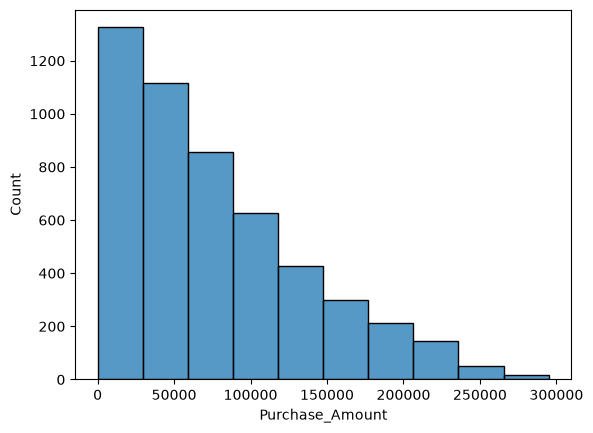

In [112]:
sns.histplot(df['Purchase_Amount'],bins=10)

<Axes: ylabel='Product_Category'>

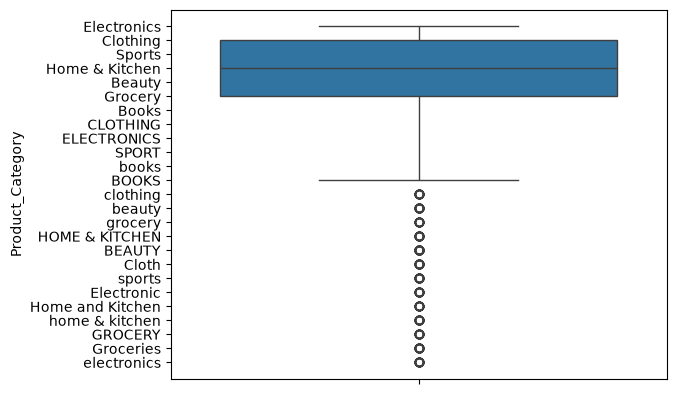

In [115]:
sns.boxplot(df['Product_Category'])

<Axes: ylabel='City'>

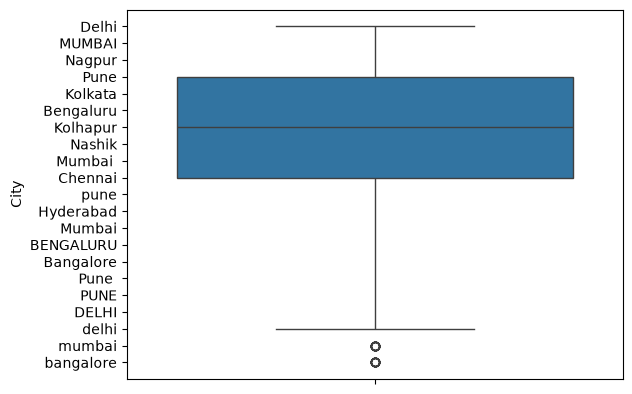

In [116]:
sns.boxplot(df['City'])

<Axes: ylabel='Payment_Method'>

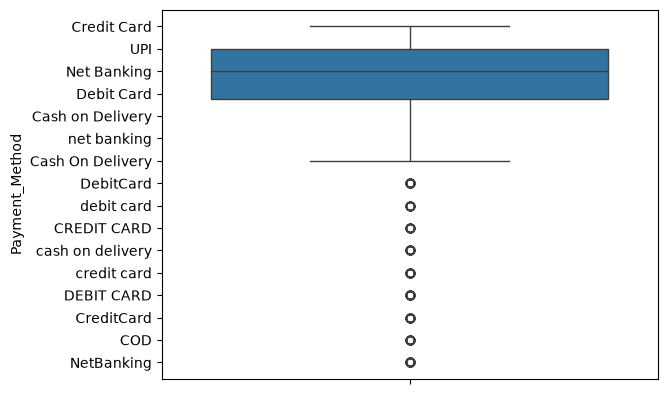

In [118]:
sns.boxplot(df['Payment_Method'])

<Axes: >

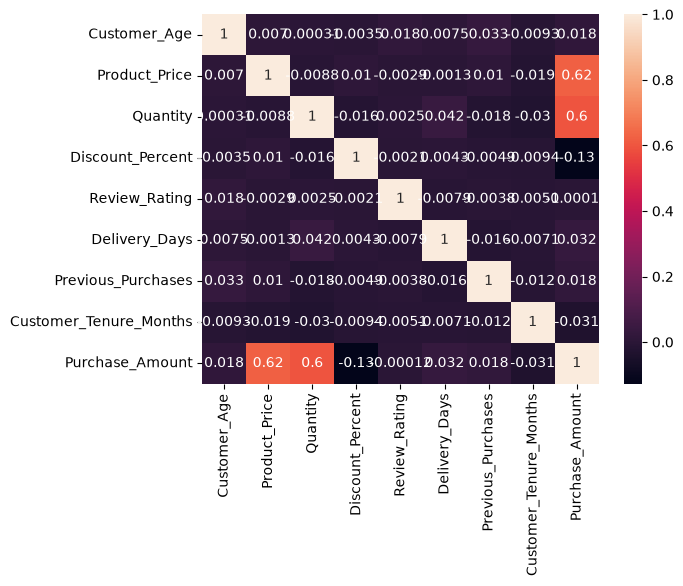

In [125]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

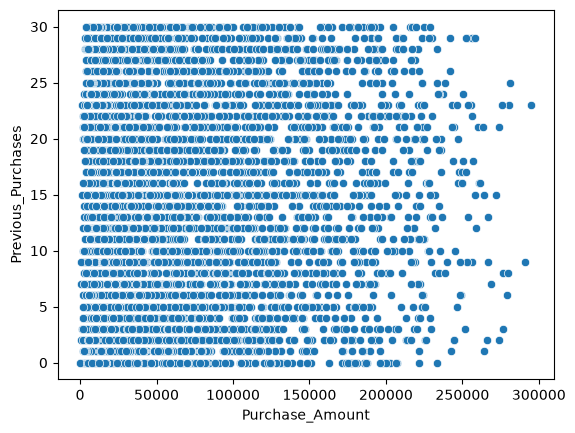

In [122]:
sns.scatterplot(x=df['Purchase_Amount'], y=df['Previous_Purchases'])
plt.show()

In [126]:
df.columns

Index(['Customer_ID', 'Customer_Age', 'Product_Category', 'Product_Price',
       'Quantity', 'Discount_Percent', 'Review_Rating', 'Delivery_Days',
       'Previous_Purchases', 'Customer_Tenure_Months', 'Payment_Method',
       'City', 'Order_Date', 'Purchase_Amount'],
      dtype='str')

<Axes: xlabel='Purchase_Amount', ylabel='Customer_Age'>

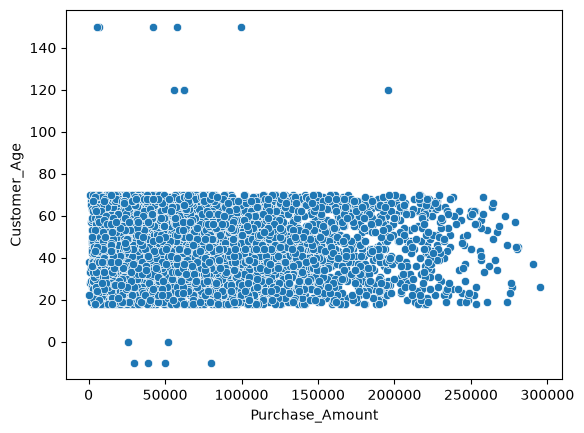

In [127]:
sns.scatterplot(x=df["Purchase_Amount"],y=df['Customer_Age'])

<Axes: xlabel='Purchase_Amount', ylabel='Customer_Tenure_Months'>

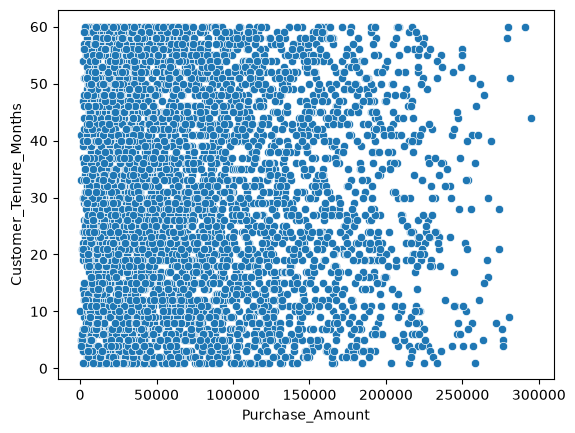

In [128]:
sns.scatterplot(x=df['Purchase_Amount'],y=df['Customer_Tenure_Months'])

In [129]:
df.corr(numeric_only=True)['Purchase_Amount'].sort_values()

Discount_Percent         -0.127829
Customer_Tenure_Months   -0.031065
Review_Rating            -0.000116
Customer_Age              0.017518
Previous_Purchases        0.018496
Delivery_Days             0.032186
Quantity                  0.597261
Product_Price             0.623892
Purchase_Amount           1.000000
Name: Purchase_Amount, dtype: float64

In [130]:
df.dtypes

Customer_ID                       string
Customer_Age                     float64
Product_Category                     str
Product_Price                    float64
Quantity                           int64
Discount_Percent                 float64
Review_Rating                    float64
Delivery_Days                    float64
Previous_Purchases               float64
Customer_Tenure_Months             int64
Payment_Method                       str
City                                 str
Order_Date                datetime64[us]
Purchase_Amount                  float64
dtype: object

In [132]:
categorical_col=df[['Product_Category','Payment_Method','City']]

In [ ]:
df['Product_Category'].value_counts()


Product_Category
Beauty              676
Clothing            659
Electronics         641
Home & Kitchen      637
Books               626
Grocery             618
Sports              613
BEAUTY               51
SPORT                50
books                44
BOOKS                44
beauty               39
sports               35
Cloth                34
home & kitchen       34
Groceries            33
ELECTRONICS          32
HOME & KITCHEN       31
CLOTHING             30
GROCERY              28
electronics          28
Electronic           27
clothing             26
grocery              22
Home and Kitchen     22
Name: count, dtype: int64

In [156]:
df.drop('Customer_ID', axis=1, inplace=True)

KeyError: "['Customer_ID'] not found in axis"

In [157]:
X=df.drop(columns=['Purchase_Amount'])
y=df['Purchase_Amount']

In [152]:
df = df.drop('Customer_ID', axis=1)

KeyError: "['Customer_ID'] not found in axis"

In [ ]:
x_encode=pd.get_dummies(X,columns=['Product_Category','Payment_Method','City'],drop_first=True)
print(x_encode.head())



   Customer_Age  Product_Price  Quantity  Discount_Percent  Review_Rating  \
0          53.0       31117.75         6              19.0            3.0   
1          34.0       43615.38         1              30.0            2.0   
2          70.0       44491.91         4              25.0            2.0   
3          21.0       16169.28         2              16.0            3.0   
4          44.0       36741.27         3               6.0            2.0   

   Delivery_Days  Previous_Purchases  Customer_Tenure_Months  \
0            7.0                14.0                      48   
1            3.0                 8.0                       9   
2            8.0                 0.0                      29   
3           11.0                 5.0                      40   
4            2.0                28.0                      42   

           Order_Date  Product_Category_BOOKS  ...  City_Mumbai   City_Nagpur  \
0 2025-04-18 04:26:00                   False  ...         False       

In [161]:
x_encode=x_encode.astype(int)
print(x_encode.head())

   Customer_Age  Product_Price  Quantity  Discount_Percent  Review_Rating  \
0            53          31117         6                19              3   
1            34          43615         1                30              2   
2            70          44491         4                25              2   
3            21          16169         2                16              3   
4            44          36741         3                 6              2   

   Delivery_Days  Previous_Purchases  Customer_Tenure_Months  \
0              7                  14                      48   
1              3                   8                       9   
2              8                   0                      29   
3             11                   5                      40   
4              2                  28                      42   

         Order_Date  Product_Category_BOOKS  ...  City_Mumbai   City_Nagpur  \
0  1744950360000000                       0  ...             0           

In [162]:
print(df.columns.tolist())

['Customer_Age', 'Product_Category', 'Product_Price', 'Quantity', 'Discount_Percent', 'Review_Rating', 'Delivery_Days', 'Previous_Purchases', 'Customer_Tenure_Months', 'Payment_Method', 'City', 'Order_Date', 'Purchase_Amount']


In [163]:
X = df.drop('Purchase_Amount', axis=1)
y = df['Purchase_Amount']

In [164]:
print(X.head())

   Customer_Age Product_Category  Product_Price  Quantity  Discount_Percent  \
0          53.0      Electronics       31117.75         6              19.0   
1          34.0         Clothing       43615.38         1              30.0   
2          70.0           Sports       44491.91         4              25.0   
3          21.0   Home & Kitchen       16169.28         2              16.0   
4          44.0      Electronics       36741.27         3               6.0   

   Review_Rating  Delivery_Days  Previous_Purchases  Customer_Tenure_Months  \
0            3.0            7.0                14.0                      48   
1            2.0            3.0                 8.0                       9   
2            2.0            8.0                 0.0                      29   
3            3.0           11.0                 5.0                      40   
4            2.0            2.0                28.0                      42   

  Payment_Method    City          Order_Date  
0  

In [165]:
X = X.drop('Customer_ID', axis=1)

KeyError: "['Customer_ID'] not found in axis"

In [166]:
categorical_cols = ['Product_Category', 'Payment_Method', 'City']

print(X[categorical_cols].head())

  Product_Category Payment_Method    City
0      Electronics    Credit Card   Delhi
1         Clothing    Credit Card  MUMBAI
2           Sports            UPI  Nagpur
3   Home & Kitchen    Net Banking    Pune
4      Electronics     Debit Card   Delhi


In [168]:
X_encode = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)
print(X_encode.head())

   Customer_Age  Product_Price  Quantity  Discount_Percent  Review_Rating  \
0          53.0       31117.75         6              19.0            3.0   
1          34.0       43615.38         1              30.0            2.0   
2          70.0       44491.91         4              25.0            2.0   
3          21.0       16169.28         2              16.0            3.0   
4          44.0       36741.27         3               6.0            2.0   

   Delivery_Days  Previous_Purchases  Customer_Tenure_Months  \
0            7.0                14.0                      48   
1            3.0                 8.0                       9   
2            8.0                 0.0                      29   
3           11.0                 5.0                      40   
4            2.0                28.0                      42   

           Order_Date  Product_Category_BOOKS  ...  City_Mumbai   City_Nagpur  \
0 2025-04-18 04:26:00                   False  ...         False       

In [171]:
X_encode.dtypes

Customer_Age        float64
Product_Price       float64
Quantity              int64
Discount_Percent    float64
Review_Rating       float64
                     ...   
City_Pune              bool
City_bangalore         bool
City_delhi             bool
City_mumbai            bool
City_pune              bool
Length: 68, dtype: object

In [172]:
bool_cols = X_encode.select_dtypes(include='bool').columns

X_encode[bool_cols] = X_encode[bool_cols].astype(int)

In [173]:
print(X_encode.head())

   Customer_Age  Product_Price  Quantity  Discount_Percent  Review_Rating  \
0          53.0       31117.75         6              19.0            3.0   
1          34.0       43615.38         1              30.0            2.0   
2          70.0       44491.91         4              25.0            2.0   
3          21.0       16169.28         2              16.0            3.0   
4          44.0       36741.27         3               6.0            2.0   

   Delivery_Days  Previous_Purchases  Customer_Tenure_Months  \
0            7.0                14.0                      48   
1            3.0                 8.0                       9   
2            8.0                 0.0                      29   
3           11.0                 5.0                      40   
4            2.0                28.0                      42   

           Order_Date  Product_Category_BOOKS  ...  City_Mumbai   City_Nagpur  \
0 2025-04-18 04:26:00                       0  ...             0       

In [181]:
df.drop_duplicates()

,Customer_Age,Product_Category,Product_Price,Quantity,Discount_Percent,Review_Rating,Delivery_Days,Previous_Purchases,Customer_Tenure_Months,Payment_Method,City,Order_Date,Purchase_Amount
0,53.0,Electronics,31117.75,6,19.0,3.0,7.0,14.0,48,Credit Card,Delhi,2025-04-18 04:26:00,152372.77
1,34.0,Clothing,43615.38,1,30.0,2.0,3.0,8.0,9,Credit Card,Mumbai,2025-07-05 17:26:00,31108.74
2,70.0,Sports,44491.91,4,25.0,2.0,8.0,0.0,29,Upi,Nagpur,2025-12-17 17:57:00,133600.19
3,21.0,Home & Kitchen,16169.28,2,16.0,3.0,11.0,5.0,40,Net Banking,Pune,2025-10-05 12:30:00,28227.29
4,44.0,Electronics,36741.27,3,6.0,2.0,2.0,28.0,42,Debit Card,Delhi,2024-09-20 11:31:00,106166.14
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5075,50.0,Books,47164.99,1,28.0,4.0,6.0,24.0,4,Debit Card,Nashik,2024-07-02 02:30:00,35747.57
5076,43.0,Grocery,2440.39,1,19.0,5.0,7.0,23.0,40,Credit Card,Hyderabad,2025-02-04 03:25:00,4491.50
5077,43.0,Home & Kitchen,42824.74,2,26.0,1.0,5.0,3.0,26,Net Banking,Nashik,2024-05-25 09:02:00,64487.05
5078,67.0,Sports,3543.80,3,18.0,2.0,11.0,23.0,11,Debit Card,Nagpur,2024-01-02 01:52:00,10366.62


In [ ]:
# Clean categorical columns
categorical_cols = ['Product_Category', 'Payment_Method', 'City']

for col in categorical_cols:
    df[col] = df[col].astype('string').str.strip()

df['City'] = df['City'].str.title()
df['Product_Category'] = df['Product_Category'].str.title()
df['Payment_Method'] = df['Payment_Method'].str.title()

# X and y
X = df.drop('Purchase_Amount', axis=1)
y = df['Purchase_Amount']

# Remove ID and date
X = X.drop(['Customer_ID', 'Order_Date'], axis=1, errors='ignore')

# Encoding
X_encode = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

# Convert True/False → 1/0
bool_cols = X_encode.select_dtypes(include='bool').columns
X_encode[bool_cols] = X_encode[bool_cols].astype(int)

# Check
print(X_encode.head())
print(X_encode.shape)

   Customer_Age  Product_Price  Quantity  Discount_Percent  Review_Rating  \
0          53.0       31117.75         6              19.0            3.0   
1          34.0       43615.38         1              30.0            2.0   
2          70.0       44491.91         4              25.0            2.0   
3          21.0       16169.28         2              16.0            3.0   
4          44.0       36741.27         3               6.0            2.0   

   Delivery_Days  Previous_Purchases  Customer_Tenure_Months  \
0            7.0                14.0                      48   
1            3.0                 8.0                       9   
2            8.0                 0.0                      29   
3           11.0                 5.0                      40   
4            2.0                28.0                      42   

   Product_Category_Books  Product_Category_Cloth  ...  City_Bengaluru  \
0                       0                       0  ...               0   
1   

In [194]:
print(X_encode)
X_encode.drop_duplicates()

      Customer_Age  Product_Price  Quantity  Discount_Percent  Review_Rating  \
0             53.0       31117.75         6              19.0            3.0   
1             34.0       43615.38         1              30.0            2.0   
2             70.0       44491.91         4              25.0            2.0   
3             21.0       16169.28         2              16.0            3.0   
4             44.0       36741.27         3               6.0            2.0   
...            ...            ...       ...               ...            ...   
5075          50.0       47164.99         1              28.0            4.0   
5076          43.0        2440.39         1              19.0            5.0   
5077          43.0       42824.74         2              26.0            1.0   
5078          67.0        3543.80         3              18.0            2.0   
5079          19.0       36951.47         3              16.0            1.0   

      Delivery_Days  Previous_Purchases

,Customer_Age,Product_Price,Quantity,Discount_Percent,Review_Rating,Delivery_Days,Previous_Purchases,Customer_Tenure_Months,Product_Category_Books,Product_Category_Cloth,...,City_Bengaluru,City_Chennai,City_Delhi,City_Hyderabad,City_Kolhapur,City_Kolkata,City_Mumbai,City_Nagpur,City_Nashik,City_Pune
0,53.0,31117.75,6,19.0,3.0,7.0,14.0,48,0,0,...,0,0,1,0,0,0,0,0,0,0
1,34.0,43615.38,1,30.0,2.0,3.0,8.0,9,0,0,...,0,0,0,0,0,0,1,0,0,0
2,70.0,44491.91,4,25.0,2.0,8.0,0.0,29,0,0,...,0,0,0,0,0,0,0,1,0,0
3,21.0,16169.28,2,16.0,3.0,11.0,5.0,40,0,0,...,0,0,0,0,0,0,0,0,0,1
4,44.0,36741.27,3,6.0,2.0,2.0,28.0,42,0,0,...,0,0,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5075,50.0,47164.99,1,28.0,4.0,6.0,24.0,4,1,0,...,0,0,0,0,0,0,0,0,1,0
5076,43.0,2440.39,1,19.0,5.0,7.0,23.0,40,0,0,...,0,0,0,1,0,0,0,0,0,0
5077,43.0,42824.74,2,26.0,1.0,5.0,3.0,26,0,0,...,0,0,0,0,0,0,0,0,1,0
5078,67.0,3543.80,3,18.0,2.0,11.0,23.0,11,0,0,...,0,0,0,0,0,0,0,1,0,0


In [195]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X_encode,y,test_size=0.2,random_state=42)

In [196]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [197]:
scaler.fit_transform(X_train)

array([[ 0.39447919,  0.84078424,  0.88011134, ..., -0.32442078,
        -0.30841953, -0.34977406],
       [-0.6306433 , -0.8884274 , -0.30014686, ..., -0.32442078,
        -0.30841953, -0.34977406],
       [-0.24622236,  0.71257842, -1.48040506, ..., -0.32442078,
        -0.30841953, -0.34977406],
       ...,
       [-0.82285376,  0.24764978, -0.30014686, ..., -0.32442078,
        -0.30841953, -0.34977406],
       [-0.24622236,  0.47254201,  1.47024044, ..., -0.32442078,
        -0.30841953, -0.34977406],
       [-1.59169563,  1.25927518, -1.48040506, ..., -0.32442078,
        -0.30841953, -0.34977406]], shape=(4064, 37))

In [198]:
print(X_train.shape)
print(X_test.shape)

(4064, 37)
(1016, 37)


In [199]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](37,)","[ 50.68, 2.44,21345.76,..., 189.7 , 609.65,-3030.6 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](37,)","['Customer_Age','Product_Price','Quantity',...,'City_Nagpur','City_Nashik', 'City_Pune']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5.452e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,37
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(37)


In [200]:
y_pred=model.predict(X_test)

In [205]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R2 Score:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R2 Score: 0.7348353722087428
MAE: 19059.095635623205
RMSE: 31199.887551934513


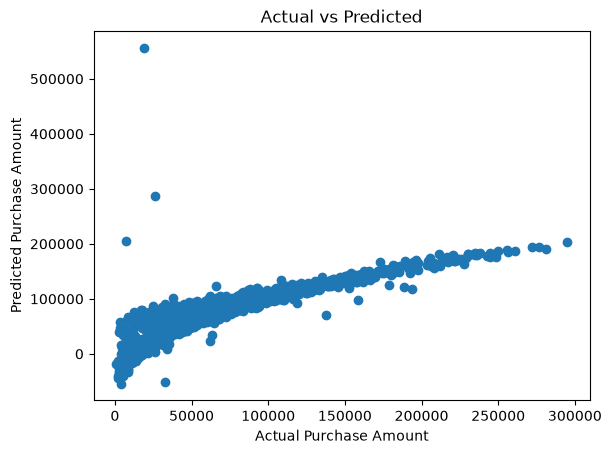

In [190]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel('Actual Purchase Amount')
plt.ylabel('Predicted Purchase Amount')
plt.title('Actual vs Predicted')
plt.show()

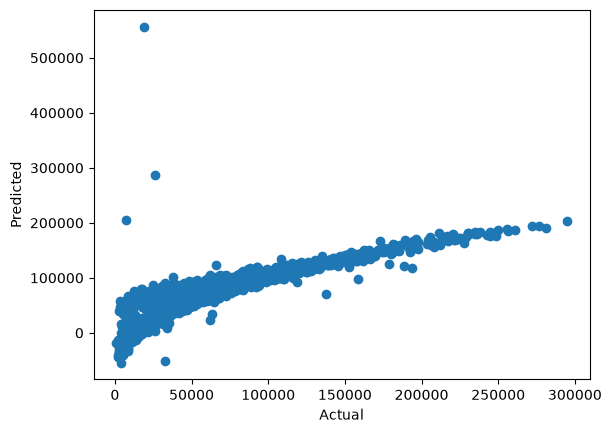

In [206]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

------------------------------------------------------------------
---------------------------------------------------------------------
-----------------------------------------------------------------

In [1]:
#import libraly 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("C:/Users/disha/Downloads/house_price_linear_regression_dataset.csv")

In [3]:
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())


  House_ID  Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0    H0001       1460         3          3         16             0.0   
1    H0002       1894         3          3         17             1.0   
2    H0003       1730         5          4         19             2.0   
3    H0004       1695         3          3         18             1.0   
4    H0005       2238         4          4          3             1.0   

   Distance_Center_km Location Furnished  Price_Lakhs  
0                13.3     Pune        No        62.62  
1                11.5   Nashik        No        82.19  
2                 1.2   Nashik        No       101.46  
3                 8.2   Nagpur       Yes        97.67  
4                 8.4   Mumbai        No       164.85  
(1000, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   House_ID        

In [4]:
#missing value
df.isnull().sum()

House_ID              0
Area_sqft             0
Bedrooms              0
Bathrooms             0
Age_Years             0
Parking_Spaces        7
Distance_Center_km    6
Location              0
Furnished             7
Price_Lakhs           0
dtype: int64

In [5]:
print(df.duplicated().sum())

0


In [6]:
df.dtypes

House_ID                  str
Area_sqft               int64
Bedrooms                int64
Bathrooms               int64
Age_Years               int64
Parking_Spaces        float64
Distance_Center_km    float64
Location                  str
Furnished                 str
Price_Lakhs           float64
dtype: object

In [7]:
#missing value
df['Parking_Spaces']=df['Parking_Spaces'].fillna(df['Parking_Spaces'].median())

In [8]:
df['Distance_Center_km']=df['Distance_Center_km'].fillna(df['Distance_Center_km'].median())

In [9]:
df['Furnished']=df['Furnished'].fillna(df['Furnished'].mode()[0])

In [10]:
print(df.isnull().sum())

House_ID              0
Area_sqft             0
Bedrooms              0
Bathrooms             0
Age_Years             0
Parking_Spaces        0
Distance_Center_km    0
Location              0
Furnished             0
Price_Lakhs           0
dtype: int64


In [11]:
df=df.drop('House_ID' , axis=1)

In [12]:
print(df.head())

   Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0       1460         3          3         16             0.0   
1       1894         3          3         17             1.0   
2       1730         5          4         19             2.0   
3       1695         3          3         18             1.0   
4       2238         4          4          3             1.0   

   Distance_Center_km Location Furnished  Price_Lakhs  
0                13.3     Pune        No        62.62  
1                11.5   Nashik        No        82.19  
2                 1.2   Nashik        No       101.46  
3                 8.2   Nagpur       Yes        97.67  
4                 8.4   Mumbai        No       164.85  


In [13]:
#Eda
numerical_col=df[['Area_sqft','Bedrooms','Bathrooms','Age_Years','Parking_Spaces','Distance_Center_km','Price_Lakhs']]
categorical_col=df[['Location','Furnished']]

In [14]:
df.corr(numeric_only=True)['Price_Lakhs'].sort_values()

Age_Years            -0.164943
Distance_Center_km   -0.123168
Parking_Spaces        0.041644
Bathrooms             0.726218
Bedrooms              0.785525
Area_sqft             0.843954
Price_Lakhs           1.000000
Name: Price_Lakhs, dtype: float64

<Axes: xlabel='Bathrooms', ylabel='Price_Lakhs'>

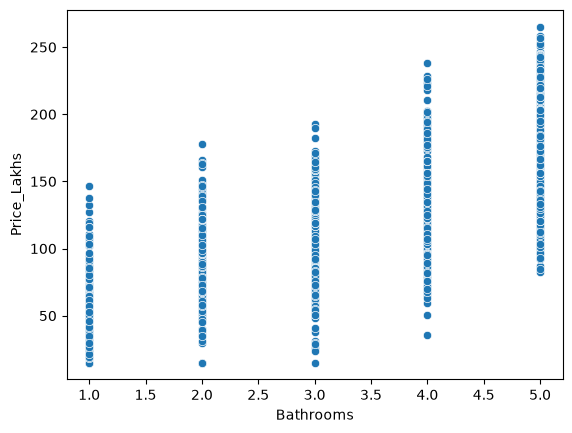

In [15]:
sns.scatterplot(x=df['Bathrooms'],y=df['Price_Lakhs'])

<Axes: xlabel='Bedrooms', ylabel='Price_Lakhs'>

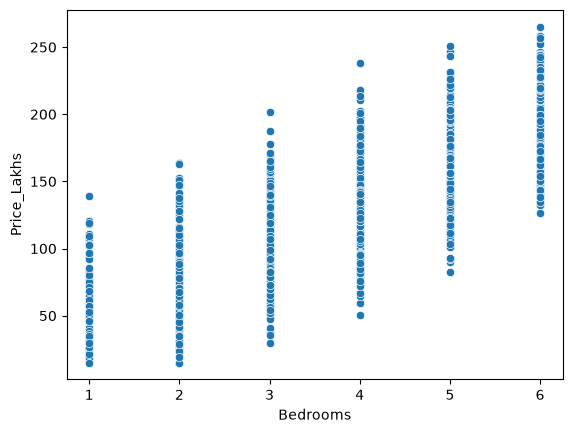

In [16]:
sns.scatterplot(x=df['Bedrooms'],y=df['Price_Lakhs'])

<Axes: xlabel='Area_sqft', ylabel='Price_Lakhs'>

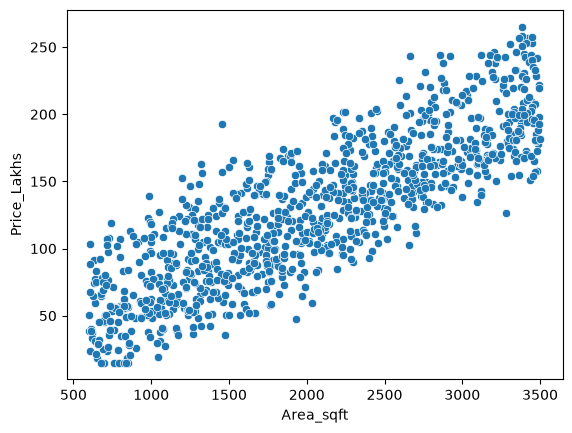

In [17]:
sns.scatterplot(x=df['Area_sqft'] ,y=df['Price_Lakhs'])

In [18]:
df.columns

Index(['Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_Years', 'Parking_Spaces',
       'Distance_Center_km', 'Location', 'Furnished', 'Price_Lakhs'],
      dtype='str')

<Axes: xlabel='Price_Lakhs', ylabel='Location'>

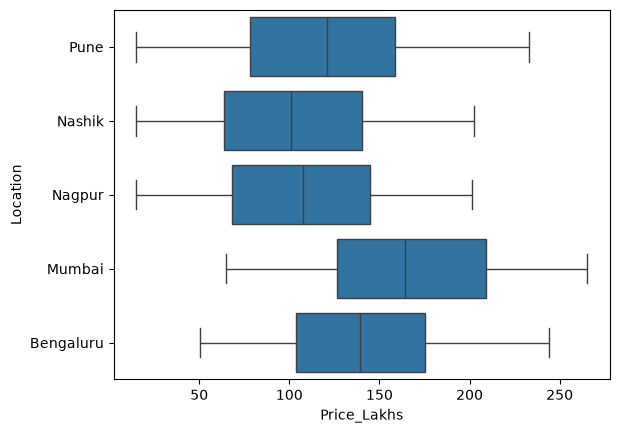

In [19]:
sns.boxplot(x=df['Price_Lakhs'],y=df['Location'])

<Axes: xlabel='Price_Lakhs', ylabel='Furnished'>

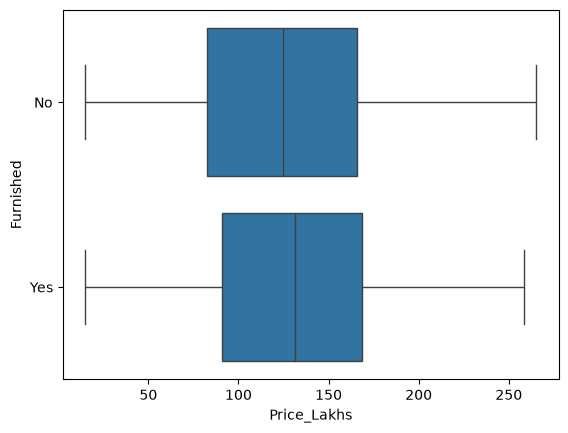

In [20]:
sns.boxplot(x=df['Price_Lakhs'],y=df['Furnished'])

<Axes: >

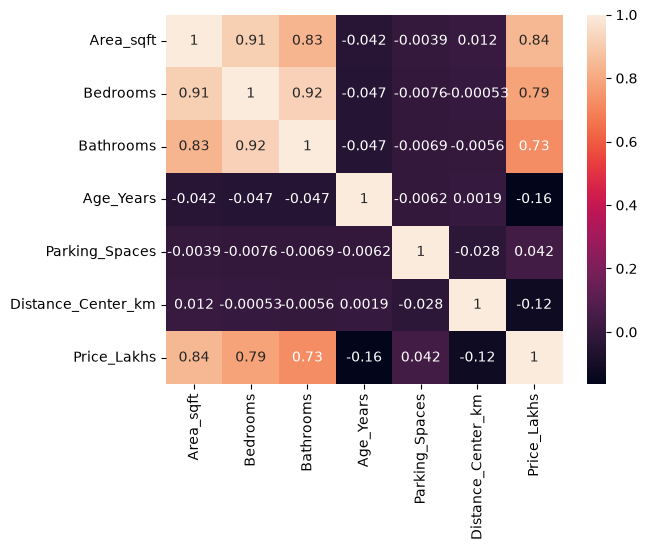

In [21]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [ ]:
X = df.drop('Price_Lakhs', axis=1)
y = df['Price_Lakhs']


     Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0         1460         3          3         16             0.0   
1         1894         3          3         17             1.0   
2         1730         5          4         19             2.0   
3         1695         3          3         18             1.0   
4         2238         4          4          3             1.0   
..         ...       ...        ...        ...             ...   
995        609         2          2          8             0.0   
996        860         1          1         19             2.0   
997       2542         4          3         10             2.0   
998       2273         4          5          7             2.0   
999       2819         6          5         18             0.0   

     Distance_Center_km   Location Furnished  Price_Lakhs  
0                  13.3       Pune        No        62.62  
1                  11.5     Nashik        No        82.19  
2                   1.2    

In [25]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['Furnished']=le.fit_transform(df['Furnished'])
print(df)

     Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0         1460         3          3         16             0.0   
1         1894         3          3         17             1.0   
2         1730         5          4         19             2.0   
3         1695         3          3         18             1.0   
4         2238         4          4          3             1.0   
..         ...       ...        ...        ...             ...   
995        609         2          2          8             0.0   
996        860         1          1         19             2.0   
997       2542         4          3         10             2.0   
998       2273         4          5          7             2.0   
999       2819         6          5         18             0.0   

     Distance_Center_km   Location  Furnished  Price_Lakhs  
0                  13.3       Pune          0        62.62  
1                  11.5     Nashik          0        82.19  
2                   1.2 

In [ ]:
df_encoded = pd.get_dummies(
    df,
    columns=['Location'],
    drop_first=True
)


   Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0       1460         3          3         16             0.0   
1       1894         3          3         17             1.0   
2       1730         5          4         19             2.0   
3       1695         3          3         18             1.0   
4       2238         4          4          3             1.0   

   Distance_Center_km Location  Furnished  Price_Lakhs  
0                13.3     Pune          0        62.62  
1                11.5   Nashik          0        82.19  
2                 1.2   Nashik          0       101.46  
3                 8.2   Nagpur          1        97.67  
4                 8.4   Mumbai          0       164.85  


In [30]:
print(df.head())

   Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0       1460         3          3         16             0.0   
1       1894         3          3         17             1.0   
2       1730         5          4         19             2.0   
3       1695         3          3         18             1.0   
4       2238         4          4          3             1.0   

   Distance_Center_km Location  Furnished  Price_Lakhs  
0                13.3     Pune          0        62.62  
1                11.5   Nashik          0        82.19  
2                 1.2   Nashik          0       101.46  
3                 8.2   Nagpur          1        97.67  
4                 8.4   Mumbai          0       164.85  


In [31]:
df_encoded = pd.get_dummies(
    df,
    columns=['Location'],
    drop_first=True
)

In [32]:
print(df)

     Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0         1460         3          3         16             0.0   
1         1894         3          3         17             1.0   
2         1730         5          4         19             2.0   
3         1695         3          3         18             1.0   
4         2238         4          4          3             1.0   
..         ...       ...        ...        ...             ...   
995        609         2          2          8             0.0   
996        860         1          1         19             2.0   
997       2542         4          3         10             2.0   
998       2273         4          5          7             2.0   
999       2819         6          5         18             0.0   

     Distance_Center_km   Location  Furnished  Price_Lakhs  
0                  13.3       Pune          0        62.62  
1                  11.5     Nashik          0        82.19  
2                   1.2 

In [33]:
df_encoded = pd.get_dummies(
    df,
    columns=['Location'],
    drop_first=True
)

In [34]:
print(df_encoded.columns.tolist())

['Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_Years', 'Parking_Spaces', 'Distance_Center_km', 'Furnished', 'Price_Lakhs', 'Location_Mumbai', 'Location_Nagpur', 'Location_Nashik', 'Location_Pune']


In [35]:
print(df_encoded.head())

   Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0       1460         3          3         16             0.0   
1       1894         3          3         17             1.0   
2       1730         5          4         19             2.0   
3       1695         3          3         18             1.0   
4       2238         4          4          3             1.0   

   Distance_Center_km  Furnished  Price_Lakhs  Location_Mumbai  \
0                13.3          0        62.62            False   
1                11.5          0        82.19            False   
2                 1.2          0       101.46            False   
3                 8.2          1        97.67            False   
4                 8.4          0       164.85             True   

   Location_Nagpur  Location_Nashik  Location_Pune  
0            False            False           True  
1            False             True          False  
2            False             True          False  
3     

In [36]:
bool_cols = df_encoded.select_dtypes(include='bool').columns

df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

In [38]:
print(df_encoded)

     Area_sqft  Bedrooms  Bathrooms  Age_Years  Parking_Spaces  \
0         1460         3          3         16             0.0   
1         1894         3          3         17             1.0   
2         1730         5          4         19             2.0   
3         1695         3          3         18             1.0   
4         2238         4          4          3             1.0   
..         ...       ...        ...        ...             ...   
995        609         2          2          8             0.0   
996        860         1          1         19             2.0   
997       2542         4          3         10             2.0   
998       2273         4          5          7             2.0   
999       2819         6          5         18             0.0   

     Distance_Center_km  Furnished  Price_Lakhs  Location_Mumbai  \
0                  13.3          0        62.62                0   
1                  11.5          0        82.19                0   
2  

In [39]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(df_encoded,
                                               y,
                                               test_size=0.20,
                                            random_state=42)

In [41]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 0., 0., 0.,...,-0.,-0., 0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Area_sqft','Bedrooms','Bathrooms',...,'Location_Nagpur', 'Location_Nashik','Location_Pune']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.126e-13
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [43]:
y_pred=model.predict(X_test)
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))

   Actual  Predicted
0   77.57      77.57
1  219.71     219.71
2  158.93     158.93
3  151.06     151.06
4  106.86     106.86
5  180.66     180.66
6  148.76     148.76
7   89.51      89.51
8   70.54      70.54
9   83.94      83.94


In [44]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
r2=r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R2 Score:", r2)
print("MAE:", mae)
print("RMSE:", rmse)


R2 Score: 1.0
MAE: 1.1271872324414289e-13
RMSE: 1.3110073087443646e-13


In [45]:
print(pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
}).head(20))

    Actual  Predicted
0    77.57      77.57
1   219.71     219.71
2   158.93     158.93
3   151.06     151.06
4   106.86     106.86
5   180.66     180.66
6   148.76     148.76
7    89.51      89.51
8    70.54      70.54
9    83.94      83.94
10   86.01      86.01
11  124.25     124.25
12   24.73      24.73
13  172.32     172.32
14   95.24      95.24
15   26.91      26.91
16   50.19      50.19
17  175.53     175.53
18   38.28      38.28
19   62.51      62.51


In [47]:
print("Target in X:", 'Price_Lakhs' in X_encode.columns)

NameError: name 'X_encode' is not defined